<center><p float="center">
  <img src="https://upload.wikimedia.org/wikipedia/commons/e/e9/4_RGB_McCombs_School_Brand_Branded.png" width="360"/>
  <img src="https://mma.prnewswire.com/media/1458111/Great_Learning_Logo.jpg?p=facebook" width="240"/>
</p></center>

<center><font size=10>Artificial Intelligence and Machine Learning</font></center>
<center><font size=6>MLS 2: Data Manipulation and Exploratory Data Analysis</font></center>


<center><p float="center">
  <img src="https://images.pexels.com/photos/29942709/pexels-photo-29942709.jpeg" width="640"/>
</p></center>

<center><font size=6>Streaming Platform Customer Churn Analysis</font></center>

# **Problem Statement**

## **Business Context**

StreamWave is a US-based, publicly listed OTT streaming platform with 40 million subscribers across North America and Western Europe. It offers three subscription tiers, Basic at \$6.99 per month, Standard at \$12.99 per month, and Premium at \$18.99 per month, spanning originals, licensed movies, live sports, and ad-supported free trials, generating approximately \$4.2 billion in annual revenue.

In a highly competitive market with established players like Netflix, Disney+, Amazon Prime Video, and Hulu, subscriber churn is the single largest operational challenge. The company faces a monthly churn rate of 5.8\%, translating to roughly 2.3 million cancellations or downgrades per month. Acquiring a replacement subscriber costs \$65 compared to just \$8 to \$12 to retain an existing one, and customer lifetime value averages \$112, well below the industry top-quartile benchmark of \$145 to \$160.

Two prior retention attempts, a blanket discount and a generic email drip, both failed because they were designed without any data-driven understanding of subscriber behavior. Meanwhile, industry growth has slowed below 3\%, competitors have pivoted to retention-first strategies, and StreamWave's board has mandated action by Q3 2026.


## **Objective**

The objective is to conduct a structured, first-cut, data-driven analysis to identify and validate the behavioral and pricing-related characteristics that
distinguish churned subscribers from retained ones, establishing a baseline for future, more granular retention analysis.

Specifically, we need to:
- Perform univariate analysis to understand the distribution of acquisition channels, subscription tiers, and engagement levels across the subscriber base.
- Use bivariate and multivariate analysis to explore how acquisition channel, subscription tier, and engagement score relate to churn status individually and in combination, to identify which segments carry the highest and lowest churn risk.
- Apply hypothesis tests to confirm that observed differences in churn rate across engagement tiers and acquisition channels are statistically significant, not random noise.

The output should be a set of directional insights and recommendations for StreamWave's marketing and retention teams, focused on channel, pricing tier, and engagement-based interventions, to inform the board's mandate to improve CLV (customer lifetime value) and reduce avoidable churn by Q3 2026.

## **Data Dictionary**

**Note:** The data extract is from 1st April 2022 to 31st March 2026.

### `subscribers.csv`

| Column | Type | Description |
|---|---|---|
| `subscriber_id` | string | Master identifier for the subscriber record. |
| `account_id` | string | Account identifier; multiple subscribers can share one account |
| `age` | int | Subscriber age in years |
| `gender` | category | Subscriber gender identity |
| `region` | category | Broad geographic region |
| `country` | category | Subscriber country |
| `signup_date` | date | Date subscriber first activated their account |
| `current_plan` | category | Active subscription tier |
| `signup_channel` | category | Acquisition channel at time of signup |
| `device_primary` | category | Primary device used for streaming |
| `household_size` | int | Number of people in subscriber's household |
| `churn_status` | binary | Whether the subscriber churned during the observation window |
| `churn_date` | date / null | Date of cancellation; null if retained |
| `price_increase_flag` | binary | Whether subscriber experienced a price hike in the last 6 months |
| `is_resub` | binary | Whether subscriber previously cancelled and reactivated |

---

### `watch_history.csv`

| Column | Type | Description |
|---|---|---|
| `session_id` | string | Unique tracking identifier for the streaming session. |
| `subscriber_id` | string | Cross-reference to the corresponding profile in the subscribers.csv dataset. |
| `session_date` | datetime | Date and time the viewing session occurred |
| `content_id` | string | Unique identifier for the content watched |
| `content_category` | category | Genre or rights category of the content |
| `content_length_minutes` | int | Total runtime of the content |
| `watch_duration_minutes` | int | Actual minutes watched in the session |
| `completion_pct` | float | Share of content watched (watch duration / content length) |
| `device_used` | category | Device used during this specific session |
| `time_of_day` | category | Time-of-day bucket when the session started |
| `engagement_score` | float | Engagement metric scaled to a 0–100 range |


---


# **Installing and Importing the Necessary Libraries**

In [ ]:
!pip install pandas==2.2.2 numpy==2.0.2 scipy==1.16.3 statsmodels==0.14.6 matplotlib==3.10.0 seaborn==0.13.2

**Note**:
- After running the above cell, kindly restart the notebook kernel (for VS Code) or runtime (for Google Colab), and run all cells sequentially from the next cell.
- On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in ***this notebook***.


**Prompt**:

<font size=3 color="4682B4">
Set up the analysis environment. Import all libraries needed for data manipulation, statistical testing, and visualization

</font>

In [ ]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns

# Configure plot styles
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 12

print("Analysis environment set up successfully.")

Analysis environment set up successfully.


# **Data Overview**

### Load all two source files

**Note**:
- In case you're using VS Code, please ensure that the notebook and the datasets are in the same folder in the local system.
- In case you're using Google Colab, please upload the datasets into Colab before moving ahead.
- The prompt for data loading in the next cell should be executed ONLY after the above points are validated.

**Prompt**:

<font size=3 color="4682B4">
StreamWave's data is available across two separate files covering subscriber profiles and viewing sessions. Load both of them, confirm they have loaded correctly
</font>

In [ ]:
df_subscribers = pd.read_csv('subscribers.csv')
df_watch_history = pd.read_csv('watch_history.csv')

print("DataFrames loaded successfully.")
print("\nShapes of the loaded DataFrames:")
print(f"df_subscribers: {df_subscribers.shape}")
print(f"df_watch_history: {df_watch_history.shape}")

DataFrames loaded successfully.

Shapes of the loaded DataFrames:
df_subscribers: (10000, 15)
df_watch_history: (306935, 11)


### Check for row counts, column counts, and samples

**Prompt**:

<font size=3 color="4682B4">
Provide the row count, column count, and a representative sample of the data for each dataset.



In [ ]:
dataframes = {
    "df_subscribers": df_subscribers,
    "df_watch_history": df_watch_history
}

for name, df in dataframes.items():
    print(f"\n--- {name} ---")
    print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")
    display(df.head())


--- df_subscribers ---
Rows: 10000, Columns: 15


,subscriber_id,account_id,age,gender,region,country,signup_date,current_plan,signup_channel,device_primary,household_size,churn_status,churn_date,price_increase_flag,is_resub
0,SUB_000001,ACC_000001,44.0,Male,North America,CA,2022-12-15,Standard,Referral,Mobile,1.0,0,NaN,0,0
1,SUB_000002,ACC_000002,NaN,Male,Western Europe,DE,2026-01-30,Basic-Ads,Free Trial,Mobile,2.0,1,2026-02-21,1,0
2,SUB_000003,ACC_000003,32.0,Female,North America,US,2024-02-25,Premium,Paid Social,TV,4.0,0,NaN,0,0
3,SUB_000004,ACC_000004,33.0,Male,North America,US,2024-06-24,Basic-Ads,Paid Social,TV,2.0,1,2026-01-13,1,0
4,SUB_000005,ACC_000005,32.0,Undisclosed,North America,US,2025-11-28,Basic-Ads,Paid Social,TV,NaN,1,2026-02-28,0,0



--- df_watch_history ---
Rows: 306935, Columns: 11


,session_id,subscriber_id,session_date,content_id,content_category,content_length_minutes,watch_duration_minutes,completion_pct,device_used,time_of_day,engagement_score
0,SES_00000001,SUB_000001,2025-08-13,CNT_00945,Licensed Movies,107,106,0.993,Mobile,Morning,50.348461
1,SES_00000002,SUB_000001,2026-02-20,CNT_21098,Live Sports,120,71,0.599,Mobile,Evening,50.348461
2,SES_00000003,SUB_000001,2025-04-22,CNT_49631,Ad-Supported Catalog,43,37,0.865,Mobile,Evening,50.348461
3,SES_00000004,SUB_000001,2025-08-02,CNT_34829,Originals,50,30,0.614,Mobile,Evening,50.348461
4,SES_00000005,SUB_000001,2025-04-05,CNT_23324,Ad-Supported Catalog,46,34,0.744,Mobile,Evening,50.348461


### Data Quality Checks: Missing Values, Duplicates, Data Types

**Prompt**:

<font size=3 color="4682B4">
For each dataset, check for the presence of missing values, duplicate values, and data type issues. If present, highlight where they occur.

In [ ]:
for name, df in dataframes.items():
    print(f"\n---- Data Quality Check for {name} ----")

    # Missing values as a rounded percentage for all columns
    print("Missing Values (%):\n", round(df.isnull().sum() / df.isnull().count() * 100, 3))

    # Duplicate rows count
    print(f"\nDuplicate rows: {df.duplicated().sum()}")

    # Data types
    print(f"\nData Types:\n {df.dtypes}")


---- Data Quality Check for df_subscribers ----
Missing Values (%):
 subscriber_id           0.00
account_id              0.00
age                     2.79
gender                  4.49
region                  0.00
country                 0.00
signup_date             0.00
current_plan            0.00
signup_channel          0.00
device_primary          1.97
household_size         12.22
churn_status            0.00
churn_date             64.99
price_increase_flag     0.00
is_resub                0.00
dtype: float64

Duplicate rows: 0

Data Types:
 subscriber_id           object
account_id              object
age                    float64
gender                  object
region                  object
country                 object
signup_date             object
current_plan            object
signup_channel          object
device_primary          object
household_size         float64
churn_status             int64
churn_date              object
price_increase_flag      int64
is_resub     

- As we observed, the biggest data quality issue is in the subscribers table - `churn_date` is missing for 64.99\% rows. The other missing values are smaller: `household_size` (12.22\%), `gender` (4.49\%), `age` (2.79\%), and `device_primary` (1.97\%).
- No duplicate rows anywhere, but all the date columns are still stored as plain text - that is the next thing we will fix in preprocessing.

### Descriptive Statistics

**Prompt**:

<font size=3 color="4682B4">
Generate the descriptive statistics of all the datasets

In [ ]:
for name, df in dataframes.items():
    print(f"\n--- Descriptive Statistics for {name} ---")
    display(df.describe(include='all'))


--- Descriptive Statistics for df_subscribers ---


,subscriber_id,account_id,age,gender,region,country,signup_date,current_plan,signup_channel,device_primary,household_size,churn_status,churn_date,price_increase_flag,is_resub
count,10000,10000,9721.000000,9551,10000,10000,10000,10000,10000,9803,8778.000000,10000.000000,3501,10000.00000,10000.000000
unique,10000,9434,NaN,4,2,8,1448,3,6,4,NaN,NaN,366,NaN,NaN
top,SUB_009984,ACC_009212,NaN,Female,North America,US,2026-03-06,Basic-Ads,Free Trial,TV,NaN,NaN,2026-03-30,NaN,NaN
freq,1,3,NaN,4264,5996,4978,30,4846,2287,4790,NaN,NaN,35,NaN,NaN
mean,NaN,NaN,40.184137,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.415812,0.350100,NaN,0.21790,0.061800
std,NaN,NaN,13.906842,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.315991,0.477025,NaN,0.41284,0.240804
min,NaN,NaN,18.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,0.000000,NaN,0.00000,0.000000
25%,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,0.000000,NaN,0.00000,0.000000
50%,NaN,NaN,39.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.000000,0.000000,NaN,0.00000,0.000000
75%,NaN,NaN,51.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.000000,1.000000,NaN,0.00000,0.000000



--- Descriptive Statistics for df_watch_history ---


,session_id,subscriber_id,session_date,content_id,content_category,content_length_minutes,watch_duration_minutes,completion_pct,device_used,time_of_day,engagement_score
count,306935,306935,306935,306935,306935,306935.000000,306935.000000,306935.000000,301907,306935,306935.000000
unique,306935,9865,366,49896,5,NaN,NaN,NaN,4,4,NaN
top,SES_00306935,SUB_003615,2026-02-28,CNT_20822,Licensed Movies,NaN,NaN,NaN,TV,Evening,NaN
freq,1,100,986,18,96917,NaN,NaN,NaN,148854,153458,NaN
mean,NaN,NaN,NaN,NaN,NaN,74.577269,48.860599,0.661673,NaN,NaN,52.424939
std,NaN,NaN,NaN,NaN,NaN,38.115064,30.159776,0.197782,NaN,NaN,19.923221
min,NaN,NaN,NaN,NaN,NaN,15.000000,0.000000,0.050000,NaN,NaN,0.000000
25%,NaN,NaN,NaN,NaN,NaN,45.000000,26.000000,0.536000,NaN,NaN,36.922475
50%,NaN,NaN,NaN,NaN,NaN,60.000000,41.000000,0.693000,NaN,NaN,52.913001
75%,NaN,NaN,NaN,NaN,NaN,105.000000,68.000000,0.816000,NaN,NaN,70.218512


**Subscribers (10,000 records)**
- Age ranges 18–70, averaging ~40 years; fairly spread across life stages (std ~14 years)
- Gender skews female (4,264 of 9,551 with data); North America dominates regions (5,996 of 10,000), with US being the top country (~5,000)
- Basic-Ads is the most common plan (~4,846 subscribers); Free Trial is the top acquisition channel (2,287)
- TV is the primary device (4,790 of 9,803 with data); average household size is ~2.4 (range 1–6)
- Churn rate is 35% - significant retention concern
- Only 6.2% are re-subscribers, suggesting win-back efforts are limited
- 21.8% were exposed to a price increase, a likely churn driver worth cross-examining

**Watch History (306,935 sessions)**
- 9,865 unique subscribers have watch activity - ~135 subscribers show no sessions at all, a passive churn risk
- Licensed Movies dominate content (96,917 sessions); Evening is peak viewing time (153,458 sessions)
- Average content length is ~75 min; average watch duration is ~49 min - users watch about 66% of content on average
- Completion rate median is 69.3% (mean 66.2%), suggesting moderate but not deep engagement
- TV is the dominant device for watching too (148,854 of 301,907), consistent with subscriber-level device data
- Wide session variance (std 30 min on watch duration) points to a mix of quick samplers and deep bingers
- The `engagement_score` ranges from a minimum value of 0 to maximum value of 98.3

- There are no missing values in the `engagement_score` column in the watch history table, however, not all subscribers are represented in this table, as some subscribers have not watched any content at all. We will have to impute the values of these missing engagement scores later.

### Orphan Records Check

In our statistical summary of the watch history table, we uncovered a critical issue: while df_watch_history logs over 300,000 active streaming sessions, it only contains records for 9,865 unique subscribers. Knowing that our dataset has exactly 10,000 total unique subscribers (df_subscribers), this leaves a gap of 135 users.

To understand this discrepancy, we must perform a **Referential Integrity Check**. This allows us to structurally verify whether those unrepresented users are missing due to a database breakdown or if they represent a true behavioral cohort of "Zero-Activation" subscribers who signed up but never played a single video. Isolating the root cause here ensures our upcoming engagement metrics aren't built on incorrect table merges.

**Prompt**:

<font size=3 color="4682B4">
Perform an referential integrity check between df_subscribers and df_watch_history using their subscriber_id columns. Find and print the count of any orphan records in the watch history table that don't exist in the subscribers table. Also, identify subscribers who have absolutely no records in the watch history table and save their IDs as zero_activation_ids

In [ ]:
# --- Referential-Integrity Check ---
# Get unique subscriber IDs from both tables
subs_ids = set(df_subscribers['subscriber_id'])
watch_ids = set(df_watch_history['subscriber_id'])

# Check for orphan records in watch history
orphans_in_watch = watch_ids - subs_ids
print(f"Orphan watch sessions (ID not in subscribers table): {len(orphans_in_watch)}")

# Check for subscribers with no watch history
zero_activation_ids = subs_ids - watch_ids
print(f"Subscribers with ZERO watch history: {len(zero_activation_ids)}")

Orphan watch sessions (ID not in subscribers table): 0
Subscribers with ZERO watch history: 135


- There are 0 orphan records in the watch history dataset. Every single streaming session in df_watch_history maps cleanly to an existing subscriber profile in df_subscribers.
- There are 135 subscribers in that have no watch session records in the watch history table.
- Because these subscribers have no watch sessions, we do not have an `engagement_score` value for them. We will have to handle these during imputation.

**Prompt**:

<font size=3 color="4682B4">
From df_subscribers, pull out only the users whose IDs are in zero_activation_ids (don't save this as a permanent new column in the main table). From that group, calculate their churn rate as a percentage using the churn_status column. Finally, print a summary showing the total number of these users and their churn rate rounded to one decimal place.

In [ ]:
# --- Flagging the Zero-Activation Cohort ---
# Filter using a boolean mask
zero_activation_cohort = df_subscribers[df_subscribers['subscriber_id'].isin(zero_activation_ids)]

# Quantify this specific cohort's churn risk
zero_act_churn_rate = zero_activation_cohort['churn_status'].mean() * 100

print(f"\n--- Zero-Activation Cohort Summary ---")
print(f"Total zero-activation users: {len(zero_activation_cohort)}")
print(f"Churn rate for zero-activation users: {zero_act_churn_rate:.1f}%")


--- Zero-Activation Cohort Summary ---
Total zero-activation users: 135
Churn rate for zero-activation users: 42.2%


- The zero-activation cohort exhibits a staggering 42.2% churn rate. This indicates that a lack of initial engagement might be directly correlated with user churn.

# **Data Preprocessing**

## Parse Data Types

- Now we are going to fix the date columns. Right now signup dates, churn dates and so on are all stored as plain text - which means we can't do any time-based math on them like calculating tenure or time between events.
- We convert every date-like column across all five tables to proper datetime format. This is a small step but everything downstream depends on it.

**Prompt**:

<font size=3 color="4682B4">
Parse and standardize all date columns to a consistent date time format across all the datasets.

In [ ]:
# Convert date columns in df_subscribers
df_subscribers['signup_date'] = pd.to_datetime(df_subscribers['signup_date'], errors='coerce')
df_subscribers['churn_date'] = pd.to_datetime(df_subscribers['churn_date'], errors='coerce')

# Convert date columns in df_watch_history
df_watch_history['session_date'] = pd.to_datetime(df_watch_history['session_date'], errors='coerce')

print("Date columns have been converted to datetime format.")

# Verify data types
print("\n--- Verified Data Types after Conversion ---")
print("df_subscribers date columns:")
print(df_subscribers[['signup_date', 'churn_date']].dtypes)
print("\ndf_watch_history date column:")
print(df_watch_history['session_date'].dtypes)

Date columns have been converted to datetime format.

--- Verified Data Types after Conversion ---
df_subscribers date columns:
signup_date    datetime64[ns]
churn_date     datetime64[ns]
dtype: object

df_watch_history date column:
datetime64[ns]


- Every date column across the five tables now shows as `datetime64[ns]` - the conversion worked cleanly and no errors were thrown.
- We are now set up for any time-based feature we want to build, like tenure in the next section.

# **Exploratory Data Analysis**

## **Univariate analysis**

A subscription business has dozens of attributes, but most don't earn a chart. A univariate plot is only worth showing if it surfaces a decision, exposes a data quality issue, or reveals a distribution the business wouldn't have guessed.

We picked subscriber distribution across acquisition channels, subscriber distribution across the various pricing tiers, engagement score distribution, and tenure distribution - each one either anchors later analysis, drives a real operational decision, or surfaces a finding on its own.

### Q1: Which acquisition channels are driving the highest volume of our subscriber base?

A subscriber's acquisition channel often dictates their initial intent, expectations, and churn likeliness. By visualizing the distribution of our user base across different signup methods-such as Free Trials, Referrals, or Partner Bundles, we can identify which marketing pipelines feed our platform the most. This foundational step is critical; it allows us to later investigate if our highest-volume acquisition strategies are inadvertently bringing in low-intent, high-churn subscribers, thereby wasting our per-user acquisition spend.

**Prompt**:

<font size=3 color="4682B4">Visualize the distribution of subscribers across different signup channels using a bar chart, sorted by the highest volume to the lowest.

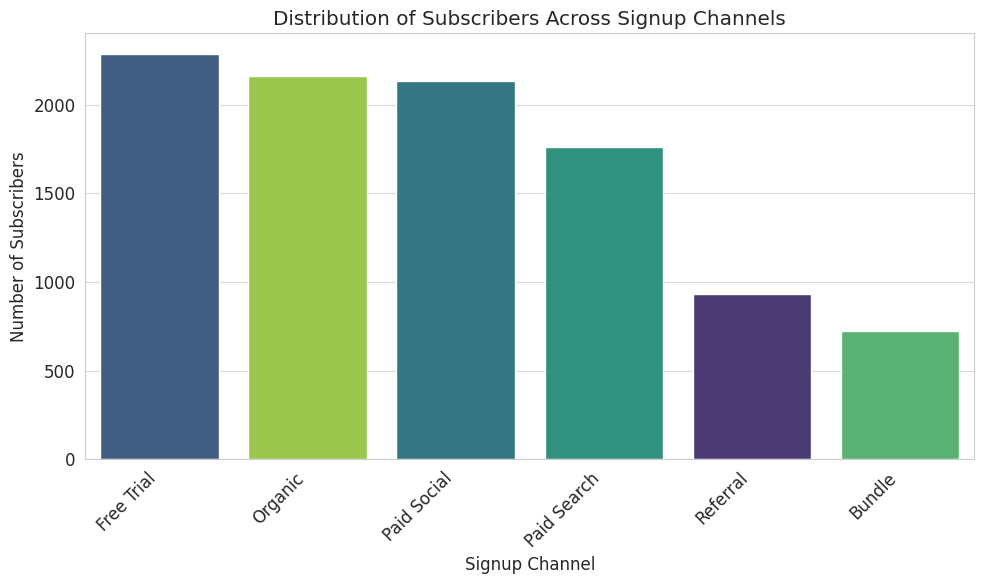

In [ ]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df_subscribers, x='signup_channel', order=df_subscribers['signup_channel'].value_counts().index, palette='viridis', hue='signup_channel', legend=False)
plt.title('Distribution of Subscribers Across Signup Channels')
plt.xlabel('Signup Channel')
plt.ylabel('Number of Subscribers')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.75)
plt.tight_layout()
plt.show()

- The Free Trial channel is the single largest driver of acquisition, bringing in roughly 2,300 subscribers.

- Organic (\~2,150) and Paid Social (\~2,100) are the next highest channels, running neck-and-neck. This indicates strong brand visibility and a heavy reliance on social media marketing for customer acquisition.

- Paid Search follows as a solid mid-tier channel, bringing in approximately 1,750 subscribers.

- Referral (\~900) and Bundle (\~700) are the lowest-performing channels in terms of raw volume.

### Q2: What is the distribution of subscribers across our pricing tiers?

Once a user is acquired, their next step in the funnel is selecting a pricing tier. Visualizing how our subscriber base distributes across these plans helps us understand our baseline revenue mix. More importantly, it highlights whether our acquisition pipeline is successfully driving users toward Premium plans, or if they are congregating at the lower, potentially higher-churn, ad-supported tiers.

**Prompt**:

<font size=3 color="4682B4">Visualize the total number of subscribers across each current subscription plan using a bar chart.

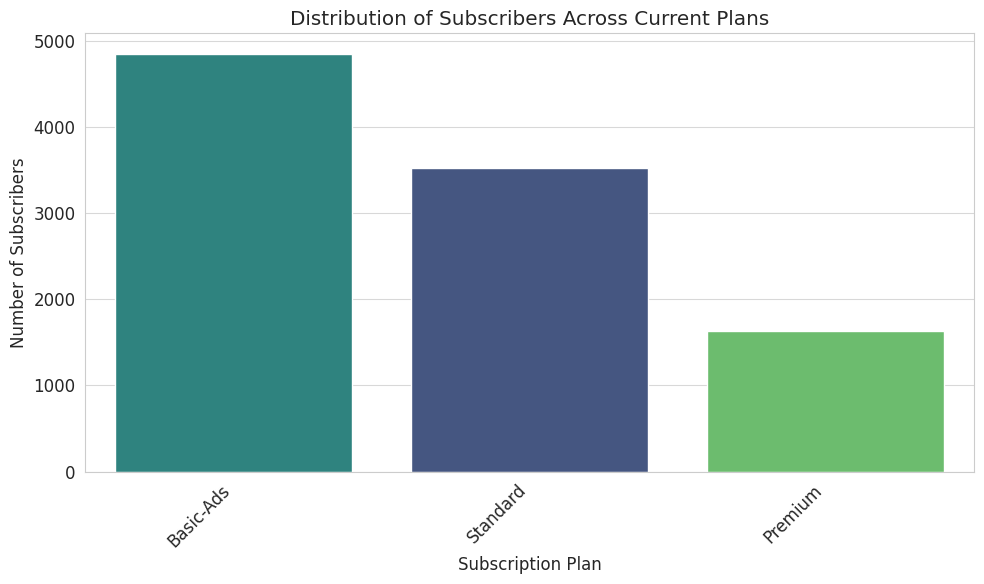

In [ ]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df_subscribers, x='current_plan', order=df_subscribers['current_plan'].value_counts().index, palette='viridis', hue='current_plan', legend=False)
plt.title('Distribution of Subscribers Across Current Plans')
plt.xlabel('Subscription Plan')
plt.ylabel('Number of Subscribers')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.75)
plt.tight_layout()
plt.show()

- Moving down the funnel from acquisition, the vast majority of users settle into the entry-level Basic-Ads tier (nearly 4,900 users). This might indicate **high price sensitivity** at the point of trial conversion or initial sign-up.

- The Standard plan captures a solid middle segment (~3,500 users). This shows that a substantial portion of the acquired base is willing to pay the $12.99 premium to bypass ads or access better streaming quality.

- The funnel narrows sharply at the top-tier Premium plan (~1,600 users). While our top-of-funnel acquisition volume (like Free Trials) is high, the conversion into our highest-value, $18.99/month tier is relatively weak.

### Q3: How are subscriber engagement levels distributed across the user base?

Simply having an active subscription doesn't mean a user is actually using the platform. Watch history alone can be noisy, so we want to look at the distribution of the Engagement Score. This will reveal whether the bulk of our user base is highly engaged, casually watching, or acting as "zombie" accounts at high risk of passive churn.

**Prompt**:

<font size=3 color="4682B4">Visualize the distribution of the engagement score using a histogram to understand the overall activity levels of our subscriber base.

In [ ]:
# Create a merged dataframe for subscriber-level analysis
unique_engagement = df_watch_history[['subscriber_id', 'engagement_score']].drop_duplicates(subset=['subscriber_id'])
merged_df = df_subscribers.merge(unique_engagement, on='subscriber_id', how='left')

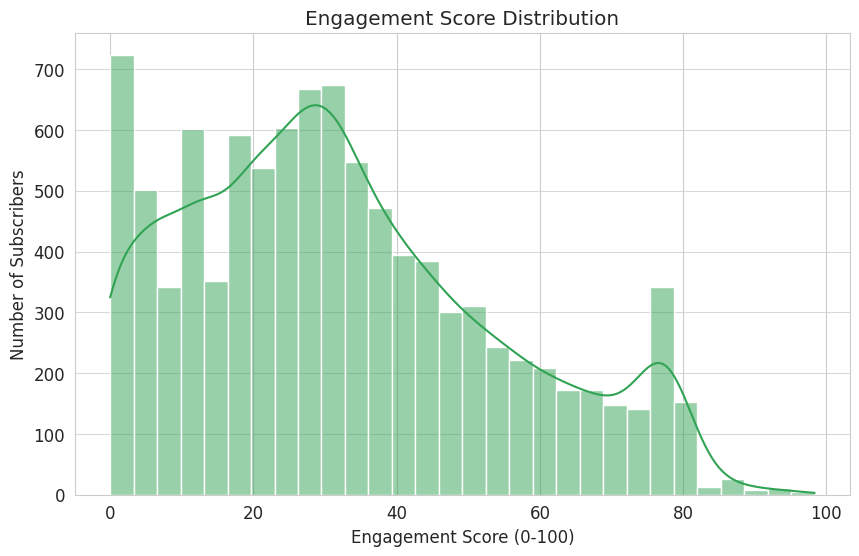

In [ ]:
# Create a deduplicated dataframe so each subscriber only has one row
df_unique_subscribers = df_watch_history.drop_duplicates(subset=['subscriber_id'])

plt.figure(figsize=(10, 6))
sns.histplot(merged_df['engagement_score'], bins=30, kde=True, color='#31a354')
plt.title('Engagement Score Distribution')
plt.xlabel('Engagement Score (0-100)')
plt.ylabel('Number of Subscribers')
plt.grid(axis='y', alpha=0.75)
plt.show()

- The overall distribution is right-skewed, meaning the vast majority of StreamWave's subscribers fall into the lower-to-middle tiers of engagement (scores between 15 and 45). The platform does not have a broadly "highly engaged" user base.

- The tallest single peak in the distribution sits at the very beginning (scores 0–5), approaching 700 subscribers. This indicates a significant cohort of inactive users who are paying but barely watching, putting them at extreme risk of passive churn.

- The bulk of the subscriber base forms a wide hump between scores of 20 and 50, with the peak around the 30 mark. This represents your average user-casual viewers who utilize the platform occasionally but have not formed a strong, consistent viewing habit.

- There is a distinct, smaller secondary peak around the 75–80 score mark. It indicates a concentrated segment of users who interact heavily with the platform.

### Q4: What is the distribution of subscriber tenure?

Understanding the lifespan of a typical subscriber is the foundation of any retention strategy. By looking at the distribution of subscriber tenure, we can identify whether we suffer from a "leaky bucket" early in the customer journey, suggesting onboarding issues, or if we are losing long-term loyalists, which might point to content staleness.

**Prompt**:

<font size=3 color="4682B4">Calculate tenure using signup_date and churn_date. If churn_date is missing, impute it with a fixed reference date of March 31, 2026. Visualize its distribution using a histogram to see when subscribers typically leave.

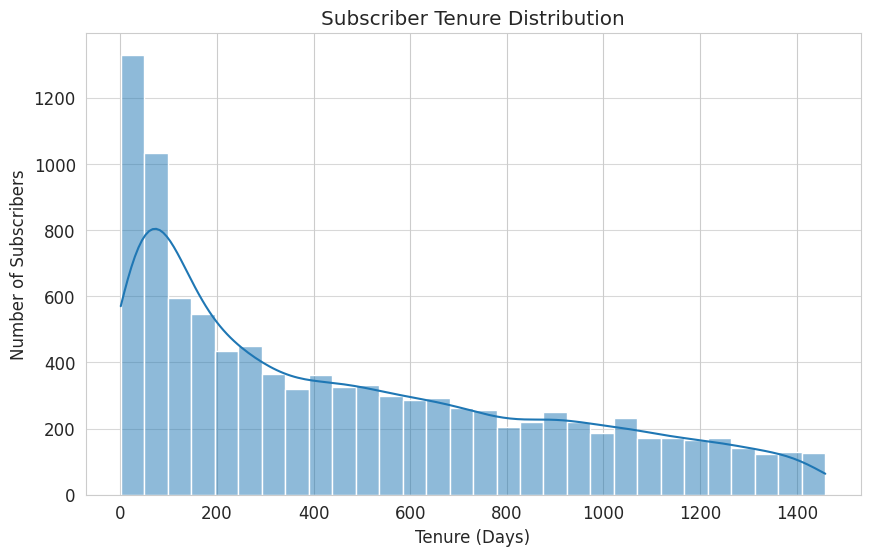

In [ ]:
# Define cutoff_date as a fixed reference point (31 March 2026)
cutoff_date = pd.to_datetime('2026-03-31')

# Use churn_date if it exists; otherwise use cutoff_date
end_dates = df_subscribers['churn_date'].fillna(cutoff_date)

# Calculate true tenure in days
df_subscribers['tenure_days'] = (end_dates - df_subscribers['signup_date']).dt.days

plt.figure(figsize=(10, 6))
sns.histplot(df_subscribers['tenure_days'], bins=30, kde=True)
plt.title('Subscriber Tenure Distribution')
plt.xlabel('Tenure (Days)')
plt.ylabel('Number of Subscribers')
plt.grid(axis='y', alpha=0.75)
plt.show()

- Extreme Right-Skewed Distribution: The histogram shows a heavy positive skew. The vast majority of subscribers have short tenures, while a long, tapering tail represents a much smaller group of long-term loyalists extending out to ~1400 days (about 4 years).
- The highest volume of subscriber churn occurs almost immediately. The peak in the first two bins (roughly 0 to 100 days) account for a big portion of the dataset(~2300 subscribers (23\%) leave within the first 3 months), with the very first bin nearing 1300 subscribers. This suggests issues with onboarding, trial conversions, or early product value realization.

## **Bivariate analysis**

While univariate analysis establishes our baseline metrics, bivariate analysis connects them to uncover the individual drivers behind subscriber behavior. For this section, we focused on three critical relationships: how acquisition channels impact engagement, how the subscription plan impacts engagement and how engagement dictates retention versus churn.

### Q1: Is there a measurable difference in engagement levels based on acquisition channel?

In our previous univariate analysis, we uncovered two critical realities: StreamWave's overall user base skews heavily toward low engagement, and our highest-volume acquisition engine is the Free Trial. To bridge these findings, we must cross-reference engagement scores with signup channels. Is our Free Trial funnel actively flooding the platform with low-intent, disengaged users, or is poor engagement a systemic issue affecting subscribers regardless of how they were acquired?

**Prompt**:

<font size=3 color="4682B4">Visualize the distribution of engagement scores across different signup channels using a box plot to see if certain channels bring in more highly engaged users.

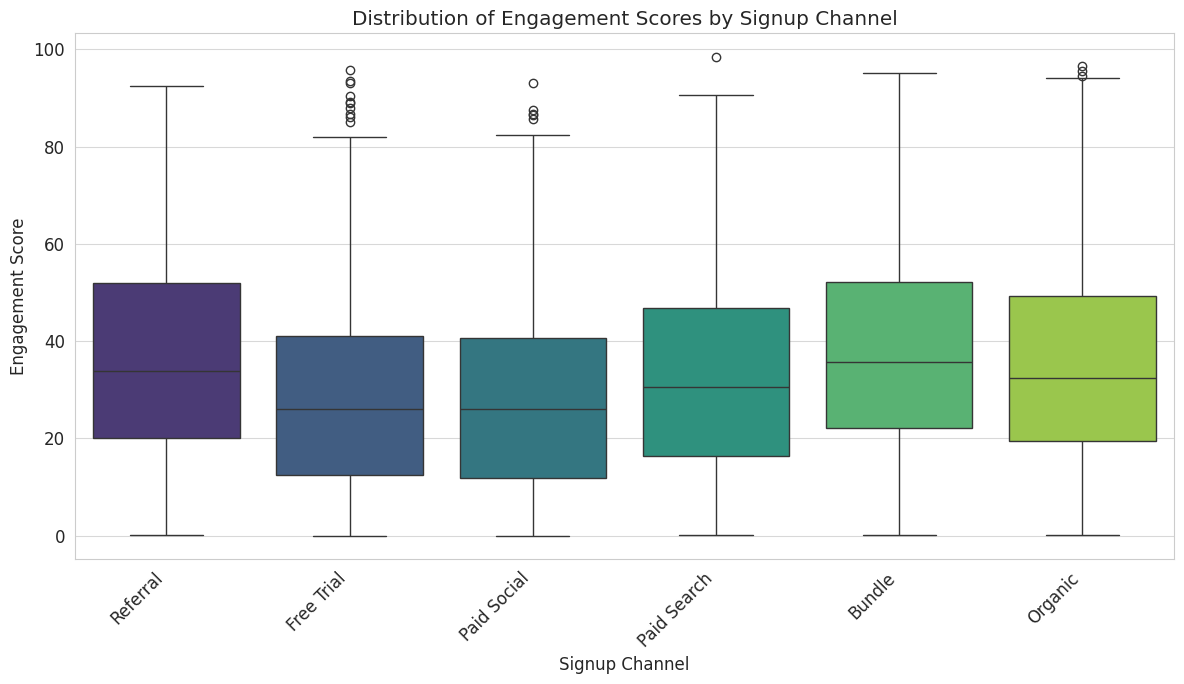

In [ ]:
plt.figure(figsize=(12, 7))
sns.boxplot(x='signup_channel', y='engagement_score', data=merged_df, palette='viridis', hue='signup_channel', legend=False)
plt.title('Distribution of Engagement Scores by Signup Channel')
plt.xlabel('Signup Channel')
plt.ylabel('Engagement Score')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.75)
plt.tight_layout()
plt.show()

- The most critical takeaway from this plot is that Free Trial-our highest-volume acquisition channel-exhibits the lowest median engagement score (sitting at around 25). Its 25th percentile is also pulled further down compared to bundle or referred users, confirming that a big chunk of our disengaged base originates right here.

- Paid Social, our third-highest acquisition driver, shares similarly low engagement metrics. The median is nearly identical to Free Trial, suggesting that sign-ups driven by social media ads are failing to convert into active, daily viewers.

- On the opposite end of the spectrum, Referral and Bundle-the channels that brought in the lowest raw volume of subscribers-show the highest median engagement scores (roughly 35). Users who are recommended by a friend or bundled through a partner demonstrate stronger, more consistent usage.

- Every channel has a outliers that extend near the 100-mark, meaning we do acquire some power users from every single source. However, the core middle 50% (the boxes) heavily dictates platform health.

### Q2: Is there a measurable difference in engagement levels based on subscription plan?

We know how users join the platform, but we also need to see if the amount they pay matches how much they actually use it. By comparing engagement scores across our different subscription plans, we can find out if people on higher-tier plans are more involved. Are Standard and Premium subscribers highly active to justify what they spend, or are they engaging at the same low levels as Basic-Ads users? If it's the latter, we face a major risk of people downgering or canceling their plans entirely.

**Prompt**:

<font size=3 color="4682B4">Visualize the distribution of engagement scores across different subscription plans using a box plot to see how user engagement levels vary between different subscription tiers.

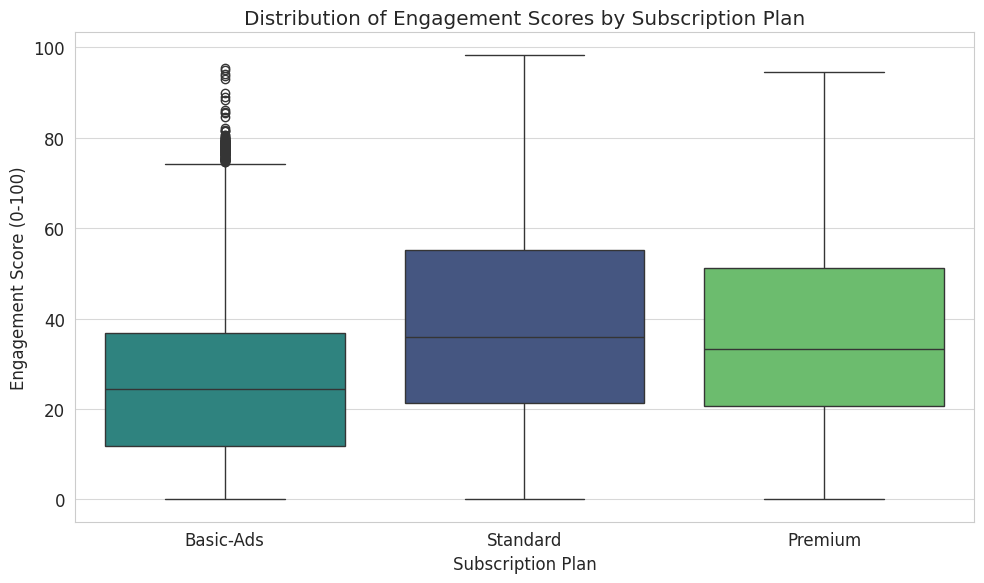

In [ ]:
# Plot the distribution using a box plot
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=merged_df,
    x='current_plan',
    y='engagement_score',
    order=['Basic-Ads', 'Standard', 'Premium'],
    palette='viridis',
    hue='current_plan',
    legend=False
)

# Formatting the plot
plt.title('Distribution of Engagement Scores by Subscription Plan')
plt.xlabel('Subscription Plan')
plt.ylabel('Engagement Score (0-100)')
plt.grid(axis='y', alpha=0.75)
plt.tight_layout()
plt.show()

- The Basic-Ads tier displays the lowest median engagement score (\~25) and a noticeably squashed Interquartile Range (IQR) compared to the higher tiers. This suggests that ad interruptions or tier-specific content limitations noticeably suppress overall subscriber viewing activity.

- The Standard plan actually yields the highest overall median engagement (\~36) and the broadest upper quartile distribution, slightly edging out the Premium tier (\~33). Higher financial investment (Premium) does not automatically guarantee higher daily streaming volumes than a Standard mid-tier plan.

- Despite having a lower overall distribution, the Basic-Ads tier features a dense cluster of high-engagement outliers stretching between 75 and 95. This reveals a highly resilient segment of power-users who are perfectly willing to watch massive amounts of content regardless of commercial breaks.

### Q3: Is lack of engagement a behavioral divider between retained and churned users?

We have already established that a high percentage of users have low engagement, particularly among our highest-volume acquisition channels like Free Trials. The critical next step is to check  whether this low engagement is the primary behavioral driver of our churn rate. By comparing the distributions of these engagement metrics between retained and churned subscribers, we can identify whether differences in viewing habits are associated with churn behavior.

**Prompt**:

<font size=3 color="4682B4">Visualize the distribution of the engagement score split by churn status using a filled KDE plot to compare the behavioral patterns of retained versus churned subscribers.

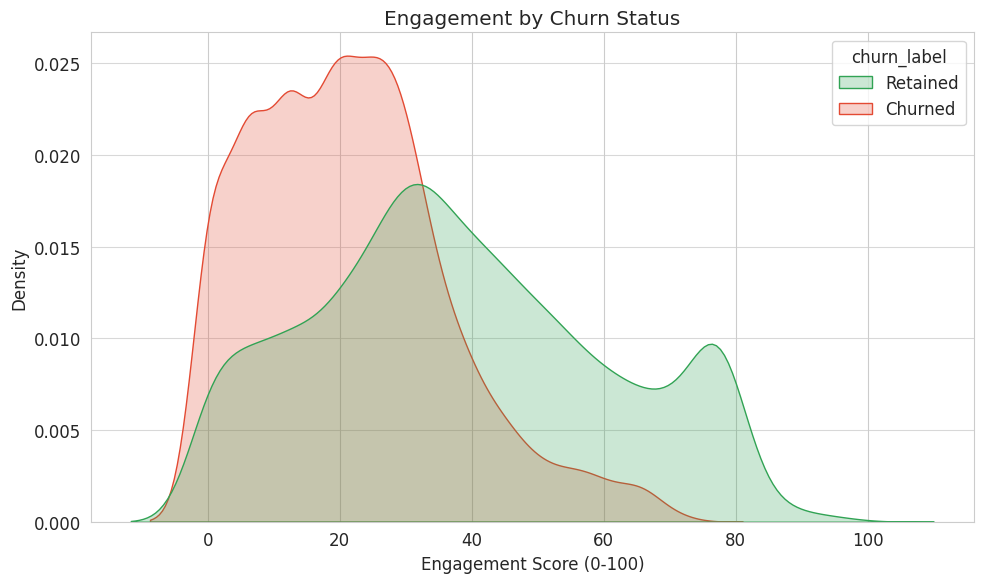

In [ ]:
plt.figure(figsize=(10, 6))
sns.kdeplot(
    data=merged_df.assign(churn_label=merged_df['churn_status'].map({0: 'Retained', 1: 'Churned'})),
    x='engagement_score',
    hue='churn_label',
    fill=True,
    common_norm=False,
    palette={'Retained': '#31a354', 'Churned': '#e34a33'}
)

plt.title('Engagement by Churn Status')
plt.xlabel('Engagement Score (0-100)')
plt.ylabel('Density')
plt.grid(axis='y', alpha=0.75)
plt.tight_layout()
plt.show()

- The distribution for churned users (red) is skewed to the left, between scores of 0 and 40. It mostly drops off after a score of 50. This shows that subscribers who will leave the platform are likely those who fail to consistently interact with the content.

- Right around an engagement score of 40, the two curves cross. Past this point, the green curve (retained users) dominates. This indicates a rough behavioral threshold: if we can get a user's engagement score roughly above 40, their probability of churning reduces.

- That secondary bump we saw in our initial univariate analysis (around the 75-80 score mark) belongs exclusively to retained users. There is almost no red density in that zone. Once users hit "power user" status, they are very unlikely to churn.

## **Multivariate analysis**

- Bivariate showed individual drivers; multivariate is where those drivers interact.
- We picked two views:  **signup channel × tenure × churn** (when does each channel's risk peak) and **plan × engagement × churn** (where to focus retention spend).

### Q1: Does a user's engagement level override the churn risk of their signup channel?

In our previous univariate and bivariate analyses, we established a clear sequence: Free Trials drive our acquisition volume but suffer from the lowest median engagement, and low engagement is the primary behavioral driver of churn. The next logical step is to evaluate these variables together.

To visualize this effectively, we must translate our continuous engagement score (0-100) into actionable behavioral segments. By dividing the user base into five equal-sized quintiles, we ensure statistical reliability in every group, by ensuring every single column has exactly 20% of the user base, preventing skewed data where one cell represents 5,000 users and another represents 5, while also creating clear user personas (from "Checked Out" to "Obsessed"). This heatmap helps us determine if pushing a user into a higher engagement tier can neutralize the inherent churn risk of their original acquisition channel, or if certain signup sources carry a baseline risk that product engagement alone cannot fix.

**Prompt**:

<font size=3 color="4682B4"> Divide the engagement score into 5 equal-sized quantiles (Checked Out, Slowing Down, Casual, Regular, Obsessed). Name the resulting categorical column eng_tier in a dataframe named merged_df.

In [ ]:
# Dynamically create 5 equal-sized engagement tiers using pd.qcut (Quantile Binning)
eng_labels = ['Checked Out', 'Slowing Down', 'Casual', 'Regular', 'Obsessed']

# Add retbins=True to extract the calculated edges
merged_df['eng_tier'], bin_edges = pd.qcut(merged_df['engagement_score'], q=5, labels=eng_labels, retbins=True)

print("Engagement tiers calculated and added to the dataframe successfully.")
print(f"Bin edges: {bin_edges}")

Engagement tiers calculated and added to the dataframe successfully.
Bin edges: [ 0.         12.31269739 24.67778465 34.6114148  51.17375243 98.36026308]


**Prompt**:

<font size=3 color="4682B4"> Create a heatmap visualizing the churn rate by signup channel and the engagement tiers to see if high engagement lowers churn universally.

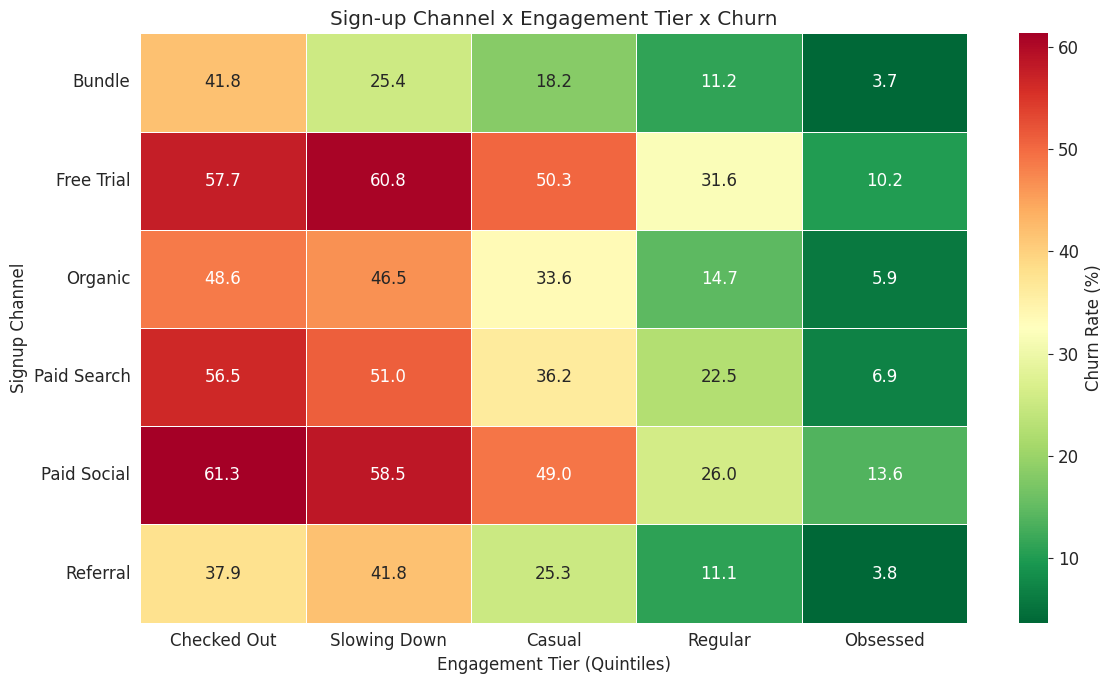

In [ ]:
# Generate pivot table for heatmap: Churn rate by Channel and Engagement Tier
channel_eng_churn = merged_df.groupby(['signup_channel', 'eng_tier'], observed=False)['churn_status'].mean().unstack() * 100

# Plot the heatmap
plt.figure(figsize=(12, 7))
sns.heatmap(channel_eng_churn, annot=True, fmt=".1f", cmap='RdYlGn_r', linewidths=.5, cbar_kws={'label': 'Churn Rate (%)'})
plt.title('Sign-up Channel x Engagement Tier x Churn')
plt.xlabel('Engagement Tier (Quintiles)')
plt.ylabel('Signup Channel')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

- The clear transition from warm colors (red/orange) on the left to cool colors (green) on the right for all channels confirms that higher engagement consistently drives down churn across every single acquisition channel. Getting a user to the "Obsessed" tier drops churn rate regardless of where they came from.

- The churn rates for the Free Trial and Paid Social channels are slightly higher compared to other channels for the same engagement tier (for the first three tiers - "Checked Out", "Slowing Down", and "Casual")

- While engagement helps, it does not completely override the channel's baseline risk. An "Obsessed" user acquired via Free Trial (10.2%) or Paid Social (13.6%) still churns at nearly three times the rate of an "Obsessed" user acquired via Bundle (3.7%) or Referral (3.8%).

- Users from Bundle and Referral channels display much stronger baseline loyalty. A "Casual" Bundle user (18.2% churn) is actually less likely to cancel than a "Regular" Paid Social user (26.0% churn).

### Q2: To what extent does high engagement shield the platform against the friction of ad-supported or premium-priced tiers?

This is arguably the most actionable view for retention marketing. We need to know if deep engagement acts as a shield against churn, even for users on the cheapest or ad-heavy tiers. By cross-tabulating subscription plan with engagement tiers to view churn rates, we can prove whether moving a user up just one engagement bracket can save their account.

**Prompt**:

<font size=3 color="4682B4">Create a heatmap visualizing the churn rate by current subscription plan and custom engagement score tiers (Checked Out, Slowing Down, Casual, Regular, Obsessed).

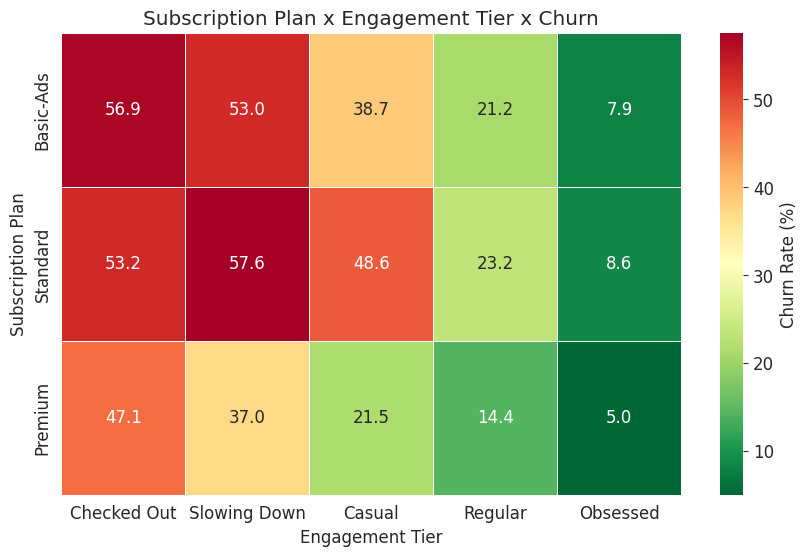

In [ ]:
# Generate table for heatmap
plan_eng_churn = merged_df.groupby(['current_plan', 'eng_tier'], observed=False)['churn_status'].mean().unstack() * 100
plan_order = ['Basic-Ads', 'Standard', 'Premium']
plan_eng_churn = plan_eng_churn.reindex(index=plan_order)

# Plotting
plt.figure(figsize=(10, 6))
sns.heatmap(plan_eng_churn, annot=True, fmt=".1f", cmap='RdYlGn_r', linewidths=.5, cbar_kws={'label': 'Churn Rate (%)'})
plt.title('Subscription Plan x Engagement Tier x Churn')
plt.xlabel('Engagement Tier')
plt.ylabel('Subscription Plan')
plt.show()

- Across all three subscription tiers, pushing a user from "Casual" to "Regular" cuts the churn rate roughly in half. Getting them to the "Obsessed" tier drops churn into the single digits (7.9%, 8.6%, and 5.0%). Frequent platform usage is your strongest retention tool.

- For Standard plan users, the highest risk of churn does not belong to the completely "Checked Out" accounts. Instead, churn peaks at a severe 57.6% when they are "Slowing Down." This indicates that users who are actively reducing their watch time are highly conscious of their declining usage and will proactively cancel their subscription.

- The Premium tier shows the lowest churn rates across almost the entire board. A "Casual" Premium user (21.5%) retains just as well as a "Regular" Standard user (23.2%). Users who commit to the highest price point exhibit a stronger baseline tolerance for periods of low usage, likely driven by higher initial intent or the sunk-cost fallacy.

- The data proves that consistent engagement can overcome the friction of an ad-supported experience. Basic-Ads users drop from a high churn rate of 56.9% when checked out to a highly stable 7.9% when obsessed. This validates that investing in engagement loops and content recommendations for the lowest-paying tier is a highly effective strategy.

# **Data Preprocessing (contd.)**

### Fill missing values in the `churn_date` attribute

We are going to clean up the missing values we flagged way back in the data quality section. We deliberately left this until *after* the analysis, because seeing the raw missingness patterns helped us pick the right imputation strategy.

- **`churn_date` - left as null.** This is the very important. A missing `churn_date` is not a data quality problem - it's the *correct* value. These subscribers haven't churned yet, so they shouldn't have a churn date. Filling them with anything (a default date, "today", or a placeholder) would silently corrupt every cohort and tenure calculation. The rule: never impute what is correctly empty.

### Fill missing values in the `engagement_score` attribute

Now, let's handle the missing values in the `engagement_score` attribute.


During our earlier referential integrity check, we identified a "Zero-Activation" cohort of 135 subscribers who have no records in the df_watch_history table. When we map engagement metrics down to the subscriber level, these users will naturally result in NaN (missing) values.

Rather than blindly dropping these rows or using a standard statistical fill (like the mean or median), we must apply a domain-driven imputation strategy:

- The Logic: Under the logical assumption that our session-logging systems are functioning flawlessly, a complete absence of viewing sessions explicitly translates to zero platform engagement.

- The Risk of Dropping: Deleting these users would create a severe survivorship bias. Because our core narrative focuses on how low engagement drives churn, removing the absolute least engaged users in our system would structurally damage our upcoming hypothesis tests.

- The Solution: We will map the engagement scores and intentionally impute these missing records with a score of 0 to accurately preserve their behavioral state.

**Prompt**:

<font size=3 color="4682B4">
Check and print the count of missing values in the engagement_score column of merged_df. Then, fill those missing values with 0 and print the remaining count of missing values to verify the imputation was successful.

In [ ]:
# --- Domain-Driven Imputation for Zero-Activation Users ---
# We impute NaNs with 0 to represent zero platform engagement.
print(f"Missing engagement scores: {merged_df['engagement_score'].isna().sum()}")

merged_df['engagement_score'] = merged_df['engagement_score'].fillna(0)

print(f"Remaining missing engagement scores: {merged_df['engagement_score'].isna().sum()}")

Missing engagement scores: 135
Remaining missing engagement scores: 0


# **Hypothesis Testing**

## For customers acquired through the largest channel by volume (Free Trials), is there a dependence between engagement level and likelihood of churn?

Free Trials represent our highest-volume acquisition channel, but they function as a leaky bucket due to a high baseline churn rate. Multivariate analysis indicates that subscribers who successfully build a consistent viewing habit may be insulated from this baseline acquisition risk.

To validate this, we isolate subscribers acquired via Free Trials and evaluate their churn rates across five distinct engagement quintiles (Checked Out, Slowing Down, Casual, Regular, and Obsessed). Testing across the full spectrum of engagement preserves behavioral nuances-such as non-linear churn spikes in transitional tiers-without the information loss caused by arbitrary binary grouping.

We employ a Chi-square Test of Independence on a $5 \times 2$ contingency table to determine if a Free Trial subscriber's churn status is statistically independent of their engagement tier.

Hypotheses:
- **$H_0$ (null)**: For Free Trial users, churn status is independent of their engagement tier. The probability of churning remains consistent regardless of whether a user is categorized as Checked Out, Slowing Down, Casual, Regular, or Obsessed.
- **$H_1$ (alternative)**: For Free Trial users, churn status is dependent on their engagement tier. The probability of churning varies significantly across different levels of platform engagement.
- **Significance level ($\alpha$)**: 0.05. Reject $H_0$ if $p < 0.05$.

Rejecting $H_0$ provides statistical proof that a Free Trial user's retention is tied to their engagement activity, validating product habit formation as a viable strategy to counteract high-risk acquisition sources.

**Prompt**:

<font size=3 color="4682B4">At 5% significance, test whether churn is associated with engagement tiers for customers in the "Free Trial" signup channel using a chi-square test of independence.

In [ ]:
from scipy.stats import chi2_contingency

# 1. Filter the dataset for Free Trial users only
free_trial_df = merged_df[merged_df["signup_channel"] == "Free Trial"].copy()

# 2. Build the 5x2 Contingency Table (5 rows for Tiers, 2 columns for Churn Status)
contingency_table = pd.crosstab(
    free_trial_df["eng_tier"], free_trial_df["churn_status"]
)

print("--- Observed 5x2 Contingency Table ---")
print(contingency_table)
print("-" * 38)

# 3. Run the Chi-Square Test of Independence
chi2, p_val, dof, expected = chi2_contingency(contingency_table)

# 4. Print Results
print(f"Chi-Square Statistic: {chi2:.4f}")
print(f"P-value:                {p_val:.4e}")

# 5. Evaluate Hypothesis at alpha = 0.05
alpha = 0.05
if p_val < alpha:
    print(f"\nResult: Reject H0. Churn status is significantly dependent on the 5 engagement quintiles within the Free Trial cohort.")
else:
    print(f"\nResult: Fail to reject H0. No statistically significant dependency found.")

--- Observed 5x2 Contingency Table ---
churn_status    0    1
eng_tier              
Checked Out   228  311
Slowing Down  205  318
Casual        214  217
Regular       264  122
Obsessed      327   37
--------------------------------------
Chi-Square Statistic: 299.5276
P-value:                1.3700e-63

Result: Reject H0. Churn status is significantly dependent on the 5 engagement quintiles within the Free Trial cohort.


- With a p-value of $1.370 \times 10^{-63}$ (effectively $0$), the result is very significant. We reject the null hypothesis ($H_0$). For Free Trial users, retention is definitively dependent on their engagement tier. Product habit formation successfully overrides the baseline structural risk of this acquisition channel.

- Looking at the raw counts, the absolute volume of churned users (column 1) actually peaks at the Slowing Down tier (318 churns) rather than the lowest Checked Out tier (311 churns) (like we observed in EDA).

- Subscribers who are actively losing momentum are statistically your highest risk-of-flight segment, outnumbering those who never fully engaged.

# **Business Insights and Recommendations**

## Business Insights

- The Free Trial and Paid Social channels generate the highest volume of new subscribers. However, these cohorts exhibit the lowest median engagement scores and carry a higher inherent churn risk regardless of their engagement level. Conversely, Referral and Bundle channels yield lower acquisition volumes but deliver subscribers with the strongest baseline engagement and retention.

- The highest volume of subscriber churn originates from users in the "Slowing Down" engagement tier, rather than the "Checked Out" tier. This trend is statistically significant among Free Trial users and peaks at a 58.7\% churn rate for the Standard subscription plan, indicating that users proactively cancel as they become conscious of their declining platform usage.

- The vast majority of subscriber churn occurs within the first 100 days of account activation. This early exodus points to substantial friction in the onboarding process or a failure to realize initial product value.

- Lower subscription costs do not equate to higher customer loyalty. The lowest-priced Basic-Ads tier experiences the highest churn proportion at nearly 40\%. The highest-priced Premium tier maintains the strongest retention, with a churn rate of approximately 22\%.

## Recommendations

**For the Marketing Team:**

- **Refocus Free Trial Strategy & Rebalance Acquisition:** Rather than withdrawing budget from high-volume Free Trial channels, revamp their specific onboarding pathways to prioritize immediate activation and early content discovery. Since multivariate analysis indicates these users can be retained if successfully engaged, focus on converting trials into active habits. Concurrently, continue to emphasize acquisition investments in Partnership Bundles and Referral programs, which inherently yield users with higher median engagement and stronger baseline loyalty.

- **Optimize Premium Tier Upselling:** Since the Premium tier boasts the lowest overall churn (22\%), identify highly engaged users in the Basic-Ads and Standard tiers for targeted upgrade campaigns. Subscribers demonstrating strong behavioral momentum are prime candidates for long-term lifetime value (LTV) maximization.

**For the Retention Team:**

- **Deploy Early-Intervention Campaigns:** Implement automated retention triggers targeting subscribers who transition from "Regular" to "Slowing Down" engagement tiers. Since users actively decelerating their watch time present the highest cancellation risk, proactive outreach should occur before they reach the "Checked Out" stage.

- **Overhaul the First 100-Day Onboarding Experience:** Redesign the initial subscriber journey to combat the immediate drop-off observed in the tenure distribution. Focus on immediate habit formation to drive new accounts roughly past the 40-point engagement score threshold, which serves as the critical crossover region for sustained retention.


# **Appendix [OPTIONAL]**

## Hypothesis Testing

### For customers on the our largest plan by volume (Basic Ads), is there a dependence between engagement level and likelihood of churn?

To determine if a dependence exists between engagement levels and the likelihood of churn for our highest-volume subscription tier (Basic-Ads), we isolate these subscribers and evaluate them across five distinct engagement quintiles (Checked Out, Slowing Down, Casual, Regular, and Obsessed).

We employ a Chi-square Test of Independence on a 5x2 contingency table to assess this relationship statistically.

Hypotheses:

-  **$H_0$ (Null Hypothesis):** For Basic-Ads users, churn status is independent of their engagement tier. (The likelihood of churn does not significantly vary across engagement levels).

- **$H_1$ (Alternative Hypothesis):** For Basic-Ads users, churn status is dependent on their engagement tier. (The likelihood of churn varies significantly depending on platform engagement).

- **Significance Level ($\alpha$):** 0.05. Reject $H_0$ if $p < 0.05$.

Rejecting $H_0$ provides statistical proof that retention for Basic-Ads users is explicitly tied to their engagement activity, validating that strong platform habits can successfully overcome the inherent friction and baseline churn risk of an ad-supported experience.

**Prompt**:

<font size=3 color="4682B4">
At 5% significance, test whether churn is associated with engagement tiers for customers on the "Basic-Ads" subscription plan using a chi-square test of independence.

In [ ]:
# 1. Filter the dataset for Basic-Ads users only
basic_ads_df = merged_df[merged_df["current_plan"] == "Basic-Ads"].copy()

# 2. Build the 5x2 Contingency Table (5 rows for Tiers, 2 columns for Churn Status)
contingency_table = pd.crosstab(
    basic_ads_df["eng_tier"], basic_ads_df["churn_status"]
)

print("--- Observed 5x2 Contingency Table ---")
print(contingency_table)
print("-" * 38)

# 3. Run the Chi-Square Test of Independence
chi2, p_val, dof, expected = chi2_contingency(contingency_table)

# 4. Print Results
print(f"Chi-Square Statistic: {chi2:.4f}")
print(f"P-value:                {p_val:.4e}")

# 5. Evaluate Hypothesis at alpha = 0.05
alpha = 0.05
if p_val < alpha:
    print(f"\nResult: Reject H0. Churn status is significantly dependent on the 5 engagement quintiles within the Basic-Ads cohort.")
else:
    print(f"\nResult: Fail to reject H0. No statistically significant dependency found.")

--- Observed 5x2 Contingency Table ---
churn_status    0    1
eng_tier              
Checked Out   553  731
Slowing Down  524  590
Casual        609  385
Regular       648  174
Obsessed      501   43
--------------------------------------
Chi-Square Statistic: 584.6601
P-value:                3.2362e-125

Result: Reject H0. Churn status is significantly dependent on the 5 engagement quintiles within the Basic-Ads cohort.


- With a p-value approaching zero (3.236e-125), the test rejects the null hypothesis. This definitively proves that for Basic-Ads subscribers, retention is dictated by platform engagement, validating that a strong product habit can successfully override the friction of an ad-supported experience.

- Unlike the Free Trial analysis where churn volume peaked at the "Slowing Down" tier, the highest volume of Basic-Ads churn stems directly from the completely "Checked Out" tier (731 cancellations). Users on this ad-supported plan are highly likely to cancel once their activity completely bottoms out.

- There is a behavioral shift at the "Casual" tier, which is the first tier where retained subscribers (609) finally outnumber churned subscribers (385). Pushing a user up the ladder to the "Obsessed" tier neutralizes the flight risk, resulting in only 43 cancellations out of 544 highly engaged users.

<font size=6 color="4682B4">Power Ahead!</font>
___